# 05 — Masked attention: causal softmax, Q/K/V, multiple heads

**Chapter 2** · suggested time: 50 min (the heart of the chapter) · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/05_attention.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

The bigram only sees the current character. We want **each position to be able to fetch information from the previous positions**, and to **choose** which ones are useful. This is exactly what attention does.

**Outline:**
1. The problem: letting a position communicate with its past (cumulative average).
2. The matrix trick and the **causal mask** (masked softmax).
3. An example of attention weights **computed by hand**.
4. **Q, K, V**: making the weights depend on the content.
5. A complete attention head, with real tensors.
6. **Multi-head attention**.

**Notation:** `B` batch, `T` positions, `C` channels (features) per position, `hs` (*head size*) = width of a head.

In [1]:
# On Google Colab: fetch the course repository (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the file minigpt.py, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cu132 | device: cuda


## 1. The problem: receiving information from the past

Suppose each position `t` has a vector of `C` features, stored in a tensor `x` of shape `(B, T, C)`. The simplest way to "summarize the past" of position `t` is to **average** the vectors of positions `0, 1, …, t`:

$$\text{xbow}[b, t] = \frac{1}{t+1} \sum_{s=0}^{t} x[b, s]$$

(*bow* = *bag of words*: we mix the past without taking order into account.)

This is a very poor form of communication (all past characters count equally), but it is the right starting point. Naive version with two loops:

In [3]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]            # (t+1, C): the past AND the current position
        xbow[b, t] = xprev.mean(dim=0)  # (C,)
print("x[0] =\n", x[0])
print("xbow[0] =\n", xbow[0])
print("Row 0 is unchanged, row 1 is the mean of rows 0 and 1, etc.")

x[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
xbow[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])
Row 0 is unchanged, row 1 is the mean of rows 0 and 1, etc.


## 2. The trick: a weighted average is a matrix product

A **lower triangular matrix** whose rows are normalized computes these averages in a single product. Read row `i` of `A` as "**how much** output `i` borrows from each position `j`".

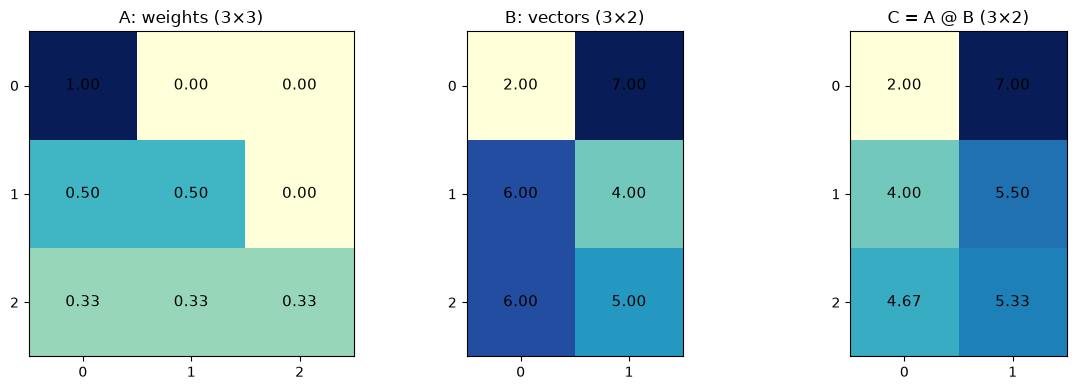

C[2,0] = 0.33×2 + 0.33×6 + 0.33×6 = 4.67


In [4]:
torch.manual_seed(42)
A = torch.tril(torch.ones(3, 3))
A = A / A.sum(1, keepdim=True)
Bm = torch.randint(0, 10, (3, 2)).float()
Cm = A @ Bm

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, M, name in zip(axes, (A, Bm, Cm), ("A: weights (3×3)", "B: vectors (3×2)", "C = A @ B (3×2)")):
    ax.imshow(M, cmap="YlGnBu")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=11)
    ax.set_title(name); ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
fig.tight_layout(); plt.show()
i, j = 2, 0
print(f"C[{i},{j}] = " + " + ".join(f"{A[i,k]:.2f}×{Bm[k,j]:.0f}" for k in range(3)) + f" = {Cm[i,j]:.2f}")

Applied to our `x`: `(T, T) @ (B, T, C) → (B, T, C)`. PyTorch applies the same matrix to each element of the batch (*broadcasting*).

In [5]:
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x
print("loops == matrix product?", torch.allclose(xbow, xbow2, atol=1e-6))

loops == matrix product? True


### Third version: start from **scores** and use a **masked softmax**

We get exactly the same weight matrix this way:
1. start from a `(T, T)` matrix of **scores** (all zeros here);
2. put `-∞` in the **forbidden** cells (the future, above the diagonal);
3. apply a **row-wise softmax**.

Why this detour? Because $e^{-\infty} = 0$: the forbidden cells get a weight of **exactly zero**, and the softmax normalizes the allowed cells so that **each row sums to 1**. And above all, in a moment, the scores will **no longer be zero**: they will be computed from the content of the tokens.

In [6]:
tril = torch.tril(torch.ones(T, T))
scores = torch.zeros((T, T))
scores = scores.masked_fill(tril == 0, float("-inf"))   # the future is forbidden
wei = F.softmax(scores, dim=-1)                         # each row: a distribution
xbow3 = wei @ x
print(wei)
print("loops == masked softmax?", torch.allclose(xbow, xbow3, atol=1e-6))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])
loops == masked softmax? True


### The causal mask: learning without cheating

We are predicting the next character. If position `t` could read position `t+1`, it would be reading **the answer** (recall: `y[t] = x[t+1]`, notebook 03). The model would get a perfect training loss and be unable to generate.

**Rule:** row `i` (the receiving position) can read column `j` (the source position) **only if `j ≤ i`**.

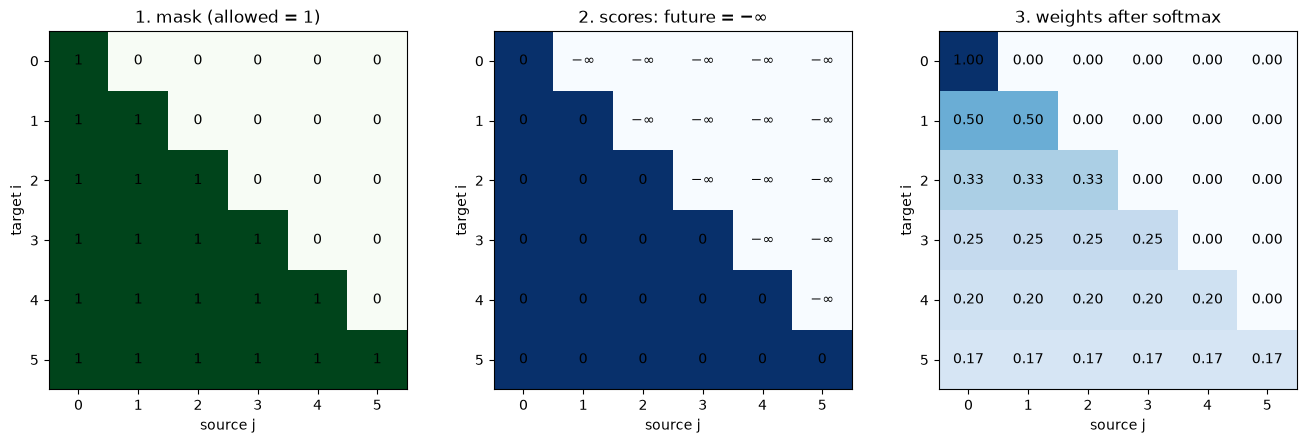

In [7]:
T_vis = 6
mask = torch.tril(torch.ones(T_vis, T_vis, dtype=torch.bool))
weights_vis = F.softmax(torch.zeros(T_vis, T_vis).masked_fill(~mask, float("-inf")), dim=-1)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for k, (ax, name) in enumerate(zip(axes, ["1. mask (allowed = 1)", "2. scores: future = −∞", "3. weights after softmax"])):
    ax.imshow(mask.float() if k < 2 else weights_vis, cmap="Greens" if k == 0 else "Blues", vmin=0, vmax=1)
    ax.set_title(name); ax.set_xlabel("source j"); ax.set_ylabel("target i")
    for i in range(T_vis):
        for j in range(T_vis):
            txt = ("1" if mask[i, j] else "0") if k == 0 else (("0" if mask[i, j] else "−∞") if k == 1 else f"{weights_vis[i, j]:.2f}")
            ax.text(j, i, txt, ha="center", va="center", fontsize=10)
fig.tight_layout(); plt.show()

**Question:** can position 3 read position 2? Position 4? *(Yes; no.)*

---
## 3. An example computed by hand: from scores to weights

Take the word **`chat`** (4 positions) and suppose we are given the following **scores** (we will see in §4 where they come from). The score `S[i, j]` says "how interested position `i` is in position `j`".

| | `c` (j=0) | `h` (j=1) | `a` (j=2) | `t` (j=3) |
|---|---|---|---|---|
| **`c`** (i=0) | 1 | 3 | 0 | 2 |
| **`h`** (i=1) | 2 | 0 | 1 | 1 |
| **`a`** (i=2) | 1 | 3 | 1 | 0 |
| **`t`** (i=3) | 0 | 2 | 2 | 1 |

**Step 1 — mask.** Everything above the diagonal becomes `−∞` (the `3` in row `c` disappears: `c` cannot see `h`).

**Step 2 — softmax, row by row.** For row `a` (i = 2), only columns 0, 1, 2 are allowed:

$$
w_{2,j} = \frac{e^{S_{2,j}}}{e^{1} + e^{3} + e^{1}} \quad\Rightarrow\quad
w_{2,\cdot} = \left[\frac{2.72}{25.52},\ \frac{20.09}{25.52},\ \frac{2.72}{25.52},\ 0\right] = [0.11,\ 0.79,\ 0.11,\ 0]
$$

Position `a` fetches **79%** of its information from `h`.

**Step 3 — mix the values.** Each position passes on a vector `v_j`. The output of position 2 is the weighted average:
$\text{out}_2 = 0.11\, v_0 + 0.79\, v_1 + 0.11\, v_2 + 0 \cdot v_3$.

Let's check with PyTorch:

In [8]:
word = list("chat")
S = torch.tensor([[1., 3., 0., 2.],
                  [2., 0., 1., 1.],
                  [1., 3., 1., 0.],
                  [0., 2., 2., 1.]])
mask4 = torch.tril(torch.ones(4, 4))
S_masked = S.masked_fill(mask4 == 0, float("-inf"))
W = F.softmax(S_masked, dim=-1)

print("Masked scores:\n", S_masked)
print("\nWeights (each row sums to 1):")
for i, c in enumerate(word):
    print(f"  {c}: " + "  ".join(f"{w:.2f}" for w in W[i].tolist()), f"  (sum = {W[i].sum():.0f})")

values = torch.tensor([[1., 0.],    # v_c
                       [0., 1.],    # v_h
                       [1., 1.],    # v_a
                       [5., 5.]])   # v_t: must NEVER reach c, h, a
out = W @ values
print("\nOutputs (weights @ values):")
for i, c in enumerate(word):
    print(f"  out_{c} = {out[i].tolist()}")
print("\nThe large value of 't' (5, 5) only appears in out_t: the future does not leak.")

Masked scores:
 tensor([[1., -inf, -inf, -inf],
        [2., 0., -inf, -inf],
        [1., 3., 1., -inf],
        [0., 2., 2., 1.]])

Weights (each row sums to 1):
  c: 1.00  0.00  0.00  0.00   (sum = 1)
  h: 0.88  0.12  0.00  0.00   (sum = 1)
  a: 0.11  0.79  0.11  0.00   (sum = 1)
  t: 0.05  0.40  0.40  0.15   (sum = 1)

Outputs (weights @ values):
  out_c = [1.0, 0.0]
  out_h = [0.8807970285415649, 0.11920291185379028]
  out_a = [0.21301394701004028, 0.8934929370880127]
  out_t = [1.1883647441864014, 1.5337865352630615]

The large value of 't' (5, 5) only appears in out_t: the future does not leak.


**Key point:** a score of `3` versus `1` already gives a weight of 0.79 versus 0.11. The softmax exponential **amplifies the differences**: a few units of score are enough for attention to focus on one position.

---
## 4. Q, K, V: weights that depend on the content

So far, the scores were **given**. In attention, each position **computes** them from its own vector `x_t`, using three **learned** linear projections:

| Vector | Computation | Role | Analogy (library) |
|---|---|---|---|
| **Query** `q_t` | `x_t @ Wq` | what the position **is looking for** | the question I ask the librarian |
| **Key** `k_t` | `x_t @ Wk` | what the position **advertises it contains** | the label on a book's spine |
| **Value** `v_t` | `x_t @ Wv` | what the position **passes on** if it is chosen | the content of the book |

The score between position `i` and position `j` is the **dot product** of `i`'s question with `j`'s label:

$$S_{ij} = \frac{q_i \cdot k_j}{\sqrt{hs}}$$

Large dot product = `j`'s key "answers" `i`'s question = large weight after softmax. Then we retrieve the weighted **values**. In matrix form, for all positions at once:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\text{mask}\!\left(\frac{Q K^\top}{\sqrt{hs}}\right)\right) V$$

![An attention head](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/05_attention_head.png)

**Why separate K and V?** What lets you **find** a piece of information (the key) is not necessarily the information you want to **retrieve** (the value). For example, a vowel may look for "the consonant just before me" (key = position) but want to retrieve "which consonant it is" (value = identity).

### Building a "look at the previous character" head by hand

To convince ourselves that Q/K can express a useful rule, let's craft weights **by hand** (a trained network can learn similar ones):
- each position `t` has as its vector `x_t` a one-hot of its **position**;
- `Wk = Id`: the key of `t` is "I am at position `t`";
- `Wq` shifts by one: the query of `t` is "I am looking for position `t − 1`".

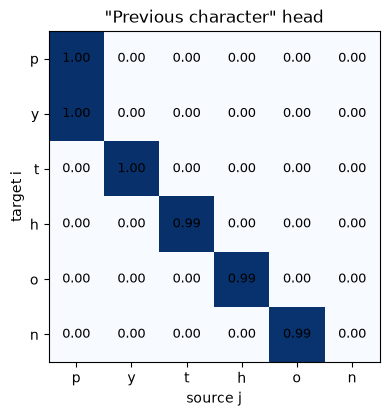

Each position (except the first) puts ~99% of its attention on the previous position.
With V = character identity, the output of 'h' would contain 't': the head has COPIED the context.


In [9]:
T4 = 6
x_pos = torch.eye(T4)                          # x_t = one-hot of position t
Wk = torch.eye(T4)                             # key:   "I am position t"
Wq = 6 * torch.diag(torch.ones(T4 - 1), -1)    # query: "I am looking for t-1" (the 6 makes the choice sharp)
q, k = x_pos @ Wq, x_pos @ Wk
S = (q @ k.T).masked_fill(torch.tril(torch.ones(T4, T4)) == 0, float("-inf"))
W = F.softmax(S, dim=-1)

letters = list("python"[:T4])
fig, ax = plt.subplots(figsize=(5, 4.3))
ax.imshow(W, cmap="Blues", vmin=0, vmax=1)
for i in range(T4):
    for j in range(T4):
        ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(T4), letters); ax.set_yticks(range(T4), letters)
ax.set_xlabel("source j"); ax.set_ylabel("target i"); ax.set_title("\"Previous character\" head")
plt.show()
print("Each position (except the first) puts ~99% of its attention on the previous position.")
print("With V = character identity, the output of 'h' would contain 't': the head has COPIED the context.")

With such a head, position `h` of `python` receives the information "the previous character was `t`": this is already more than a bigram. A real model **learns** its `Wq`, `Wk`, `Wv` by gradient descent, and can discover much subtler rules whose meaning even we do not know.

---
## 5. An attention head with real tensors

Let's move on to random `nn.Linear` projections on a small batch: `B = 2`, `T = 4`, `C = 6`, `hs = 3`.

- `nn.Linear(C, hs, bias=False)` transforms **each position separately**: `(B, T, C) → (B, T, hs)`. It does **not** make positions communicate.
- Communication happens in `q @ k.transpose(-2, -1)`: each query is compared with each key **of the same example**.

x       : (2, 4, 6)
q       : (2, 4, 3)
k       : (2, 4, 3)
v       : (2, 4, 3)
scores  : (2, 4, 4)
weights : (2, 4, 4)
out     : (2, 4, 3)


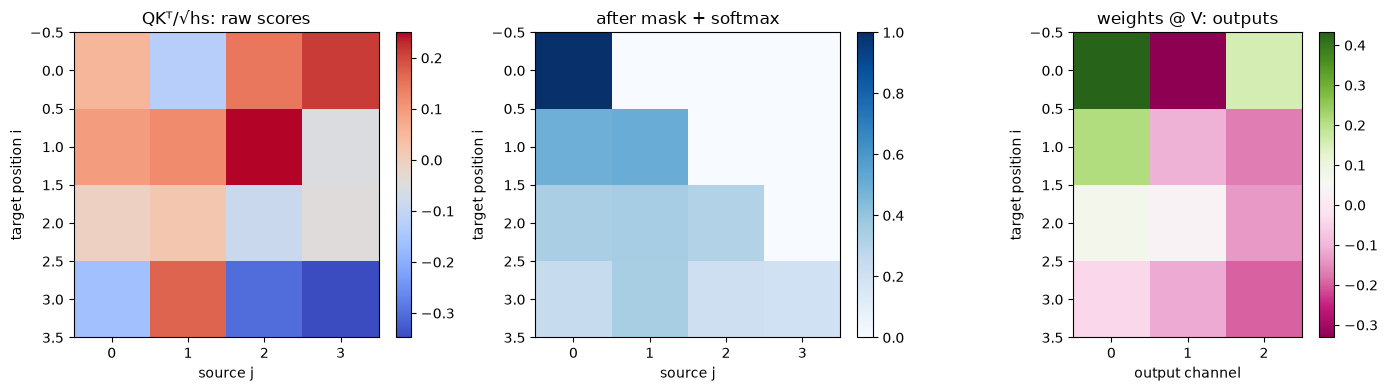

In [10]:
torch.manual_seed(2026)
B, T, C, hs = 2, 4, 6, 3
x_att = torch.randn(B, T, C)
query = nn.Linear(C, hs, bias=False)
key = nn.Linear(C, hs, bias=False)
value = nn.Linear(C, hs, bias=False)

q, k, v = query(x_att), key(x_att), value(x_att)             # (B, T, hs) each
scores = q @ k.transpose(-2, -1) / math.sqrt(hs)             # (B, T, T)
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
weights = F.softmax(scores.masked_fill(~causal, float("-inf")), dim=-1)  # (B, T, T)
out = weights @ v                                            # (B, T, hs)

for name, t in [("x", x_att), ("q", q), ("k", k), ("v", v), ("scores", scores), ("weights", weights), ("out", out)]:
    print(f"{name:8s}: {tuple(t.shape)}")
assert torch.allclose(weights.sum(-1), torch.ones(B, T))
assert (weights[:, ~causal] == 0).all()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, M, title, cmap in [(axes[0], scores[0], "QKᵀ/√hs: raw scores", "coolwarm"),
                           (axes[1], weights[0], "after mask + softmax", "Blues"),
                           (axes[2], out[0], "weights @ V: outputs", "PiYG")]:
    im = ax.imshow(M.detach(), cmap=cmap); ax.set_title(title); plt.colorbar(im, ax=ax, fraction=.046)
axes[0].set_xlabel("source j"); axes[1].set_xlabel("source j"); axes[2].set_xlabel("output channel")
for ax in axes: ax.set_ylabel("target position i")
plt.tight_layout(); plt.show()

### Why transpose K?

For one example of the batch, `Q` and `K` have shape `(T, hs)`. We want to compare **each row of Q with each row of K**: we need `(T, hs) @ (hs, T) = (T, T)`. Cell `(i, j)` is the dot product $q_i \cdot k_j$. `transpose(-2, -1)` swaps the last two dimensions and leaves the batch dimension alone.

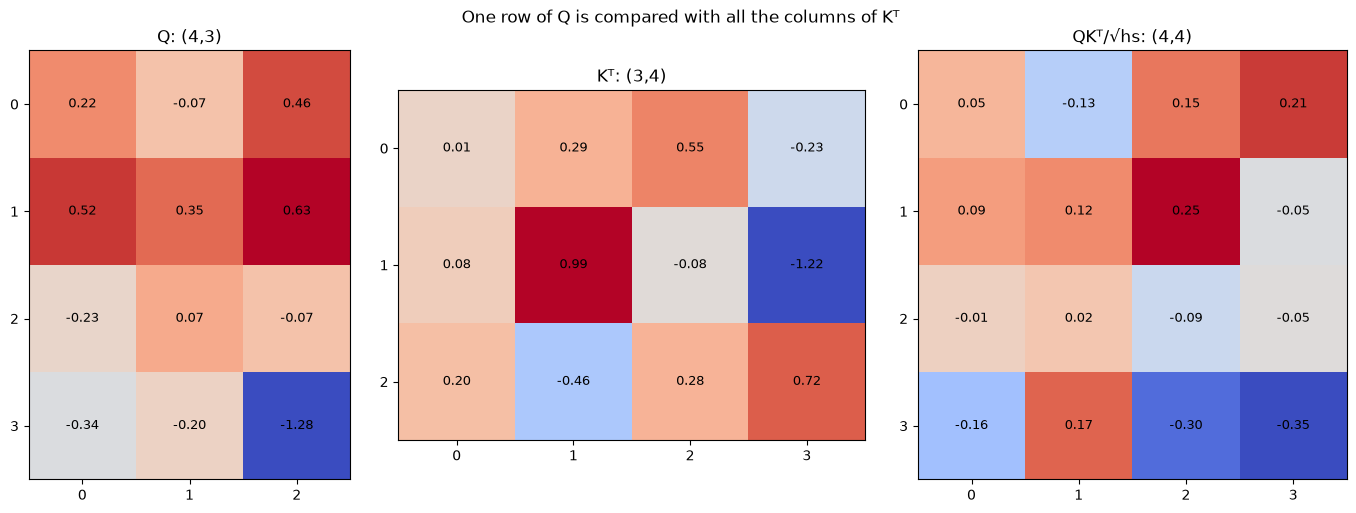

score(2,1) = (q_2 · k_1) / √3 = 0.0190 = 0.0190


In [11]:
q0, k0 = q[0].detach(), k[0].detach()
qk0 = q0 @ k0.T / math.sqrt(hs)
fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 4, 4]})
for ax, M, title in [(axes[0], q0, f"Q: ({T},{hs})"), (axes[1], k0.T, f"Kᵀ: ({hs},{T})"), (axes[2], qk0, f"QKᵀ/√hs: ({T},{T})")]:
    ax.imshow(M, cmap="coolwarm")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(title); ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
fig.suptitle("One row of Q is compared with all the columns of Kᵀ"); fig.tight_layout(); plt.show()
i, j = 2, 1
print(f"score({i},{j}) = (q_{i} · k_{j}) / √{hs} = {(q0[i] @ k0[j]).item() / math.sqrt(hs):.4f} = {qk0[i, j]:.4f}")

### Why does `weights @ V` give back one vector per position?

A row of the weights contains `T` coefficients; it is used to compute the weighted sum of the `T` vectors of `V` (each of size `hs`). We get **one** vector of size `hs` per position: `(T, T) @ (T, hs) → (T, hs)`. The weights are over **positions**, the values are over **features**.

In [12]:
A0, V0, Y0 = weights[0].detach(), v[0].detach(), out[0].detach()
position, channel = 2, 0
terms = " + ".join(f"{A0[position, j]:.2f}×{V0[j, channel]:.2f}" for j in range(T))
print(f"out[{position},{channel}] = {terms} = {Y0[position, channel]:.4f}")
print("The weight of the future position 3 is zero: it contributes nothing.")

out[2,0] = 0.34×0.43 + 0.35×-0.01 + 0.31×-0.23 + 0.00×-0.47 = 0.0715
The weight of the future position 3 is zero: it contributes nothing.


### Why divide by $\sqrt{hs}$?

If `q` and `k` have components of variance 1, their dot product (a sum of `hs` terms) has a variance of about `hs`. With large scores, the softmax becomes **almost an argmax**: all the attention goes to a single position, and the gradients of the other positions become nearly zero. Dividing by $\sqrt{hs}$ brings the variance of the scores back to ~1 (Vaswani et al., 2017, §3.2.1).

> Variance measures how far values spread from their mean. The larger it is, the more spread out the values are.

variance of q·k          : 18.44   (≈ hs = 16)
variance of q·k / √hs    : 1.15   (≈ 1)


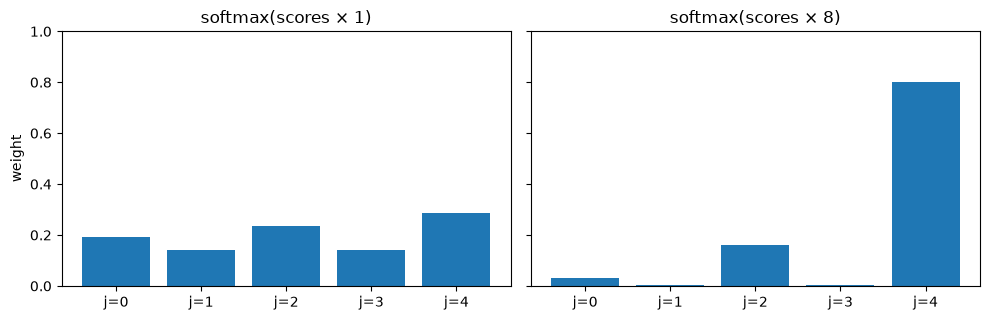

In [13]:
torch.manual_seed(1337)
hs_test = 16
k_ = torch.randn(4, 8, hs_test); q_ = torch.randn(4, 8, hs_test)
print(f"variance of q·k          : {(q_ @ k_.transpose(-2, -1)).var():.2f}   (≈ hs = {hs_test})")
print(f"variance of q·k / √hs    : {(q_ @ k_.transpose(-2, -1) * hs_test**-0.5).var():.2f}   (≈ 1)")

example = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, scale in zip(axes, [1, 8]):
    p = torch.softmax(example * scale, dim=-1)
    ax.bar(range(5), p); ax.set_ylim(0, 1); ax.set_title(f"softmax(scores × {scale})")
    ax.set_xticks(range(5), [f"j={j}" for j in range(5)])
axes[0].set_ylabel("weight"); fig.tight_layout(); plt.show()

### The `Head` class

Everything we have just done, packaged in an `nn.Module` (this is the code in `minigpt.py`):
- `register_buffer("tril", ...)`: the mask is saved with the model and follows `.to(device)`, but **is not a parameter**;
- `self.tril[:T, :T]`: we can call the head on a sequence **shorter** than `block_size` (useful during generation);
- the `dropout` on the weights will be explained in notebook 06.

In [14]:
class Head(nn.Module):
    """One causal self-attention head."""

    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)    # "what I contain"
        self.query = nn.Linear(n_embd, head_size, bias=False)  # "what I am looking for"
        self.value = nn.Linear(n_embd, head_size, bias=False)  # "what I pass on"
        # The mask is NOT a parameter: register_buffer stores it with the model
        # (and moves it to the GPU with it) without the optimizer touching it.
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                          # (B, T, hs)
        q = self.query(x)                                        # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # (B, T, T) scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # forbid the future
        wei = F.softmax(wei, dim=-1)                             # each row sums to 1
        wei = self.dropout(wei)
        v = self.value(x)                                        # (B, T, hs)
        return wei @ v                                           # (B, T, hs)


torch.manual_seed(0)
head = Head(n_embd=32, head_size=8, block_size=16, dropout=0.0)
x = torch.randn(1, 10, 32)
y1 = head(x)

# Causality test: changing position 7 must not change ANY output before 7
x2 = x.clone(); x2[0, 7] = torch.randn(32)
y2 = head(x2)
diff = (y1 - y2).abs().amax(dim=-1)[0]
print("change in the output, position by position:", [f"{d:.2f}" for d in diff.tolist()])
assert diff[:7].max() == 0, "the future leaked!"
print("Positions 0 to 6 unchanged: the head is causal.")

change in the output, position by position: ['0.00', '0.00', '0.00', '0.00', '0.00', '0.00', '0.00', '0.22', '0.19', '0.17']
Positions 0 to 6 unchanged: the head is causal.


---
## 6. Multi-head attention: several questions in parallel

A head computes **only one** weight distribution per position: it can only ask **one question** at a time ("where is the previous vowel?"). But to predict the next character, several pieces of information are useful at the same time: the previous character, the start of the word, the last space, the name of the speaker…

**Solution:** run `h` heads **in parallel**, each with its own `Wq`, `Wk`, `Wv`, then **concatenate** their outputs along the channel axis.

![Multi-head attention](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/05_multi_head.png)

- With `C = 64` and `h = 4`, each head has `hs = 64 / 4 = 16` channels; concatenation gives back `4 × 16 = 64` channels.
- The final **projection** `proj` (Linear `C → C`) mixes what the heads have found and prepares the residual addition (notebook 07).
- We concatenate along `dim=-1` (the channels): the `T` positions are **never** concatenated with each other.
- Cost: `h` heads of size `C/h` cost as much as **one** head of size `C`. We gain diversity without paying more.

In [15]:
class MultiHeadAttention(nn.Module):
    """Several heads in parallel, concatenated then projected back to n_embd channels."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)]
        )
        self.proj = nn.Linear(n_head * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)    # (B, T, n_head*hs)
        return self.dropout(self.proj(out))                     # (B, T, n_embd)


torch.manual_seed(0)
mha = MultiHeadAttention(n_embd=64, n_head=4, block_size=32, dropout=0.0)
x = torch.randn(2, 10, 64)
print("input:", tuple(x.shape))
for i, h in enumerate(mha.heads):
    print(f"  head {i} -> {tuple(h(x).shape)}")
print("concatenation ->", tuple(torch.cat([h(x) for h in mha.heads], dim=-1).shape))
print("output ->", tuple(mha(x).shape))
print("parameters:", minigpt.count_parameters(mha),
      "= 4 heads × 3 × (64×16) + proj (64×64 + 64)")

input: (2, 10, 64)


  head 0 -> (2, 10, 16)


  head 1 -> (2, 10, 16)
  head 2 -> (2, 10, 16)


  head 3 -> (2, 10, 16)


concatenation -> (2, 10, 64)
output -> (2, 10, 64)
parameters: 16448 = 4 heads × 3 × (64×16) + proj (64×64 + 64)


In notebook 09, we will display the **attention weights of a trained model**: we will see that the heads specialize.

---
## 7. What to keep in mind (notes from the grand master Karpathy)

- **Attention is a communication mechanism.** Positions are nodes in a directed graph; each node aggregates information from the nodes that point to it, with weights that depend on the data.
- **Attention has no notion of space or order.** It acts on a *set* of vectors. This is why we will have to **add position information** to the embeddings (notebook 08).
- **The examples in a batch never communicate**: the computations are done independently for each `b`.
- **Encoder vs decoder:** removing the `masked_fill` line gives an **encoder** attention (everyone sees everyone). We keep it: we are a **decoder**.
- **Self- vs cross-attention:** here Q, K, V come from the **same** `x` (*self*). In cross-attention (notebook 04), Q comes from the decoder and K, V from an encoder.

## Summary

- The attention weights form a `(T, T)` matrix per example and per head; each row is a distribution (softmax).
- **Causal mask:** score `−∞` on the future before the softmax ⇒ weight exactly 0 ⇒ no leak of the answer.
- $\text{softmax}(\text{mask}(QK^\top/\sqrt{hs}))\,V$: Q·K decide **where to look**, V decides **what to retrieve**.
- `Wq`, `Wk`, `Wv` (and `proj`) are the **only** parameters; the mask and the softmax have none.
- **Multi-head:** `h` independent heads of size `C/h`, concatenated along the channels, then projected.

**Check your understanding**
1. Why does `Q @ K.transpose(-2, -1)` have shape `(B, T, T)` and not `(B, T, C)`?
2. In `weights @ V`, what is summed, and with which coefficients?
3. What would happen during training if we forgot the mask? And during generation?
4. Why do we concatenate the heads with `dim=-1` and not along `T`?
5. What is the difference between the bigram table and the matrices `Wq`, `Wk`, `Wv`?

**Next → 06:** attention allowed positions to **receive** information. The FeedForward will let them **process** it.

### References
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.2 (*Scaled Dot-Product Attention*, *Multi-Head Attention*).
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and its code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) — sections "the mathematical trick in self-attention" and "self-attention".
- D. Bahdanau, K. Cho, Y. Bengio, [*Neural Machine Translation by Jointly Learning to Align and Translate*](https://arxiv.org/abs/1409.0473), 2014 — the first attention.
- 3Blue1Brown, [*Attention in transformers, visually explained*](https://www.youtube.com/watch?v=eMlx5fFNoYc) — excellent visual intuition for Q, K, V.
- J. Alammar, [*The Illustrated Transformer*](https://jalammar.github.io/illustrated-transformer/), section *Self-Attention in Detail*.
- Illustration of the attention block: dvgodoy, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Transformer,_attention_block_diagram.png), CC BY 4.0.